# Spatial distribution and particle energy spectrum
Load final records `(x, y, z, E_total)` as native-endian float64: positions in pc, total proton energy in GeV. The current simulation writes `particles_loss.bin`; `particle_loss.bin` is also supported.

Particles have equal statistical weight. Here the particle spectral energy distribution (SED) means $E^2 dN/dE$, energy per natural-log energy interval. It is not a photon spectrum, flux, or absolute astrophysical luminosity. The binary contains no initial energies or run metadata, so it cannot establish individual energy losses. Source parameters below must match the run that generated the file.


In [9]:
from pathlib import Path
import re
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
plt.rcParams.update({'figure.dpi': 120})

DATA_FILE = Path('particles_loss_t1e8_nH1.0.bin')
SOURCE_FILE = Path('hadronic_loss.cpp')
source = SOURCE_FILE.read_text()
def parameter(name):
    match = re.search(r'\b' + re.escape(name) + r'\s*=\s*([0-9.eE+\-]+)\s*;', source)
    if match is None:
        match = re.search(r'^\s*#define\s+' + re.escape(name) + r'\s+([0-9.eE+\-]+)', source, re.M)
    if match is None:
        raise ValueError(f'Set {name} manually: cannot read source value.')
    return float(match.group(1))

E_MIN = parameter('E_min')
E_MAX = parameter('E_max')
T_END = parameter('T_end')
VZ = parameter('v_z')
MP = parameter('m_p')
EXPECTED_N = int(parameter('N_particles'))
# Override these values if the source has changed since the simulation run.
if not DATA_FILE.exists():
    raise FileNotFoundError('Run hadronic_loss.cpp to generate the binary first.')
size = DATA_FILE.stat().st_size
if size == 0 or size % 32:
    raise ValueError('Expected a nonzero file size divisible by 32 bytes (4 doubles).')
data = np.fromfile(DATA_FILE, dtype='=f8').reshape(-1, 4)
if not np.isfinite(data).all():
    raise ValueError('Non-finite positions or energies in binary.')
positions, energy = data[:, :3], data[:, 3]
kinetic = energy - MP
n = len(data)
if n < 2 or np.any(kinetic <= 0):
    raise ValueError('Need at least two particles with positive kinetic energy.')
if n != EXPECTED_N:
    print(f'WARNING: {n} records versus {EXPECTED_N} particles in source.')
mean = positions.mean(axis=0)
center = np.array([0., 0., VZ*T_END])
r = np.linalg.norm(positions - center, axis=1)
print(f'File: {DATA_FILE}; particles: {n:,}')
print('Mean position [pc]:', mean)
print('Expected advection center [pc]:', center)
print('Coordinate standard deviations [pc]:', positions.std(axis=0, ddof=1))
print('Covariance [pc²]:\n', np.cov(positions, rowvar=False))
print('Total energy min / median / max [GeV]:', np.percentile(energy, [0, 50, 100]))
print('RMS radius about expected center [pc]:', np.sqrt(np.mean(r*r)))


File: particles_loss_t1e8_nH1.0.bin; particles: 10,000
Mean position [pc]: [2.00280297e+02 1.12382223e+02 2.99985323e+06]
Expected advection center [pc]: [      0.       0. 3000000.]
Coordinate standard deviations [pc]: [10137.42721345 10244.31285384 10457.02275493]
Covariance [pc²]:
 [[ 1.02767431e+08  1.21678826e+05 -1.04414646e+06]
 [ 1.21678826e+05  1.04945946e+08 -7.58239611e+05]
 [-1.04414646e+06 -7.58239611e+05  1.09349325e+08]]
Total energy min / median / max [GeV]: [3.24997201e+00 5.69789953e+00 4.05091926e+03]
RMS radius about expected center [pc]: 17807.450066973557


## Spatial projections and coordinate distributions
The energy-dependent diffusion produces a mixture of spatial widths, so a single Gaussian is not generally the appropriate prediction for the full population.


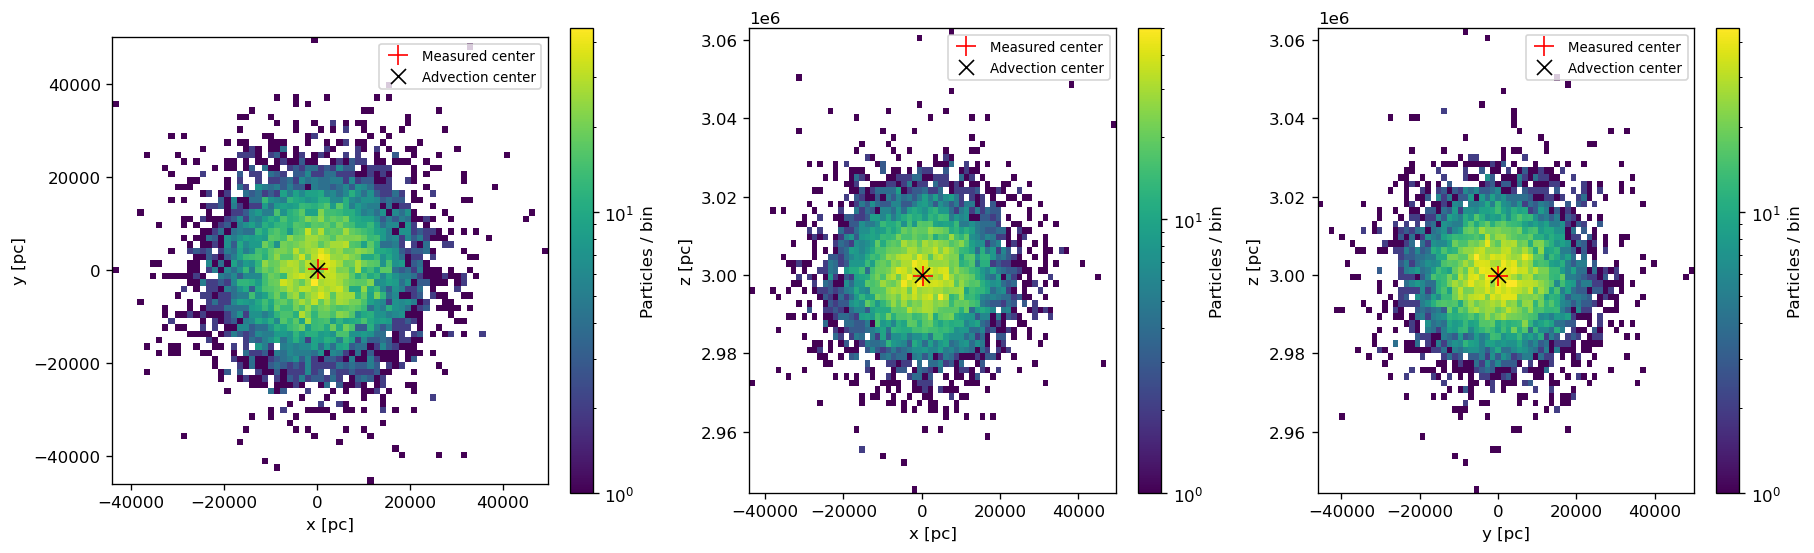

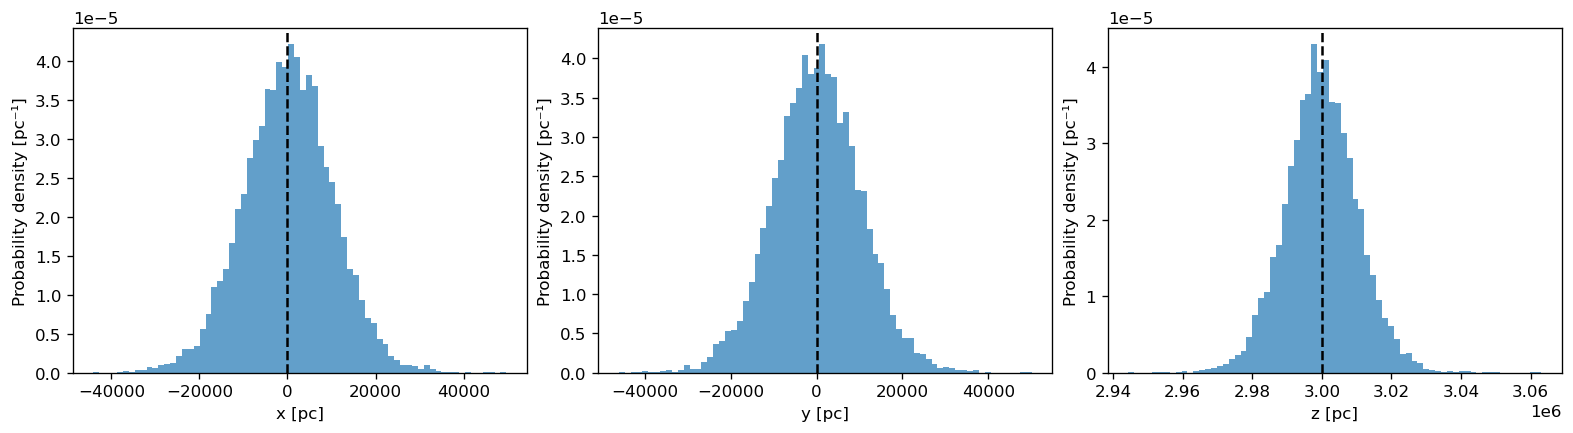

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)
for ax, (a, b) in zip(axes, [(0, 1), (0, 2), (1, 2)]):
    h = ax.hist2d(positions[:, a], positions[:, b], bins=70, norm=LogNorm(), cmin=1)
    ax.plot(mean[a], mean[b], 'r+', ms=12, label='Measured center')
    ax.plot(center[a], center[b], 'kx', ms=9, label='Advection center')
    ax.set(xlabel=f'{"xyz"[a]} [pc]', ylabel=f'{"xyz"[b]} [pc]', aspect='equal')
    ax.legend(fontsize=8)
    fig.colorbar(h[3], ax=ax, label='Particles / bin')
plt.show()
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), constrained_layout=True)
for j, ax in enumerate(axes):
    ax.hist(positions[:, j], bins=70, density=True, alpha=0.7)
    ax.axvline(center[j], color='k', linestyle='--')
    ax.set(xlabel=f'{"xyz"[j]} [pc]', ylabel='Probability density [pc⁻¹]')
plt.show()


## Differential spectrum and SED
Logarithmic bins require dividing counts by their **linear** bin widths to obtain $dN/dE$. Error bars use $\sqrt{N_{bin}}$ as an approximate counting uncertainty. Empty bins are omitted from log plots; the highest-energy bins may be poorly sampled.

The dashed curve is the expected injected $E^{-2}$ spectrum normalized to the number of simulated particles, integrated exactly over each bin. It is a reference, not the measured initial sample or a cooled-spectrum prediction.


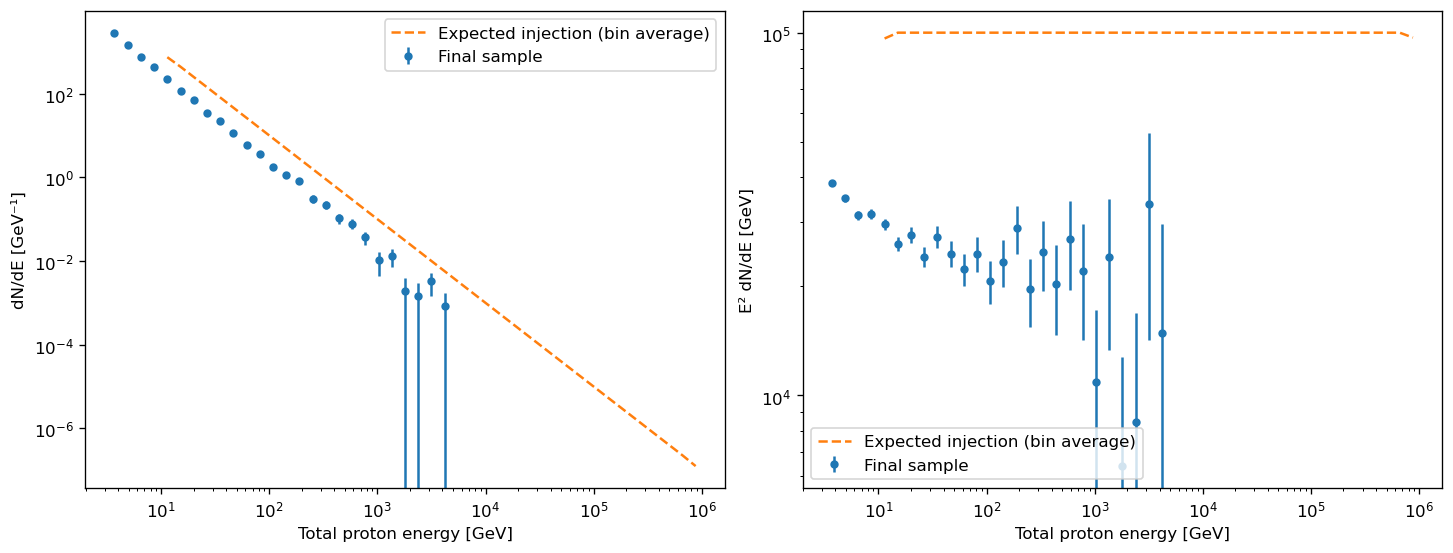

Counts per energy bin: [2929 2013 1362 1037  733  488  391  257  220  149  102   85   54   46
   43   22   21   13   13    8    3    5    1    1    3    1    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0]


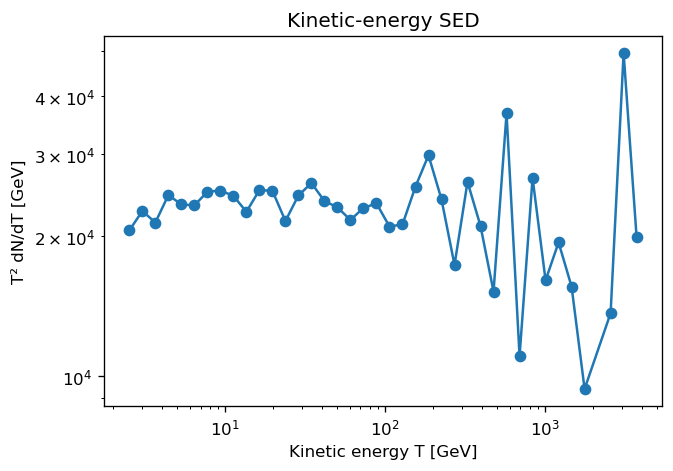

In [11]:
edges = np.geomspace(min(energy.min(), E_MIN)*0.99, max(energy.max(), E_MAX)*1.01, 46)
counts, _ = np.histogram(energy, bins=edges)
widths = np.diff(edges)
ec = np.sqrt(edges[:-1]*edges[1:])
dnde = counts / widths
error = np.sqrt(counts) / widths
mask = counts > 0
C = 1.0 / (1.0/E_MIN - 1.0/E_MAX)
lo = np.maximum(edges[:-1], E_MIN)
hi = np.minimum(edges[1:], E_MAX)
expected_counts = np.zeros_like(ec)
valid = hi > lo
expected_counts[valid] = n*C*(1/lo[valid] - 1/hi[valid])
reference = expected_counts / widths
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for ax, factor, ylabel in zip(axes, [np.ones_like(ec), ec**2],
                              ['dN/dE [GeV⁻¹]', 'E² dN/dE [GeV]']):
    ax.errorbar(ec[mask], (factor*dnde)[mask], yerr=(factor*error)[mask], fmt='o', ms=4, label='Final sample')
    good = reference > 0
    ax.plot(ec[good], (factor*reference)[good], '--', label='Expected injection (bin average)')
    ax.set(xscale='log', yscale='log', xlabel='Total proton energy [GeV]', ylabel=ylabel)
    ax.legend()
plt.show()
print('Counts per energy bin:', counts)
# Kinetic-energy SED: distinct from total-energy SED at lower energies.
kedges = np.geomspace(kinetic.min()*0.99, kinetic.max()*1.01, 41)
kcounts, _ = np.histogram(kinetic, bins=kedges)
kcenters = np.sqrt(kedges[:-1]*kedges[1:])
good = kcounts > 0
fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(kcenters[good], (kcenters**2*kcounts/np.diff(kedges))[good], 'o-')
ax.set(xlabel='Kinetic energy T [GeV]', ylabel='T² dN/dT [GeV]', title='Kinetic-energy SED')
plt.show()


## Energy-dependent spatial spread
Plot the radius from the predicted advection center against final energy. RMS values use every particle in each energy bin; sparsely populated bins are marked separately. Since energies evolve, final energy alone does not determine a particle's integrated diffusion history.


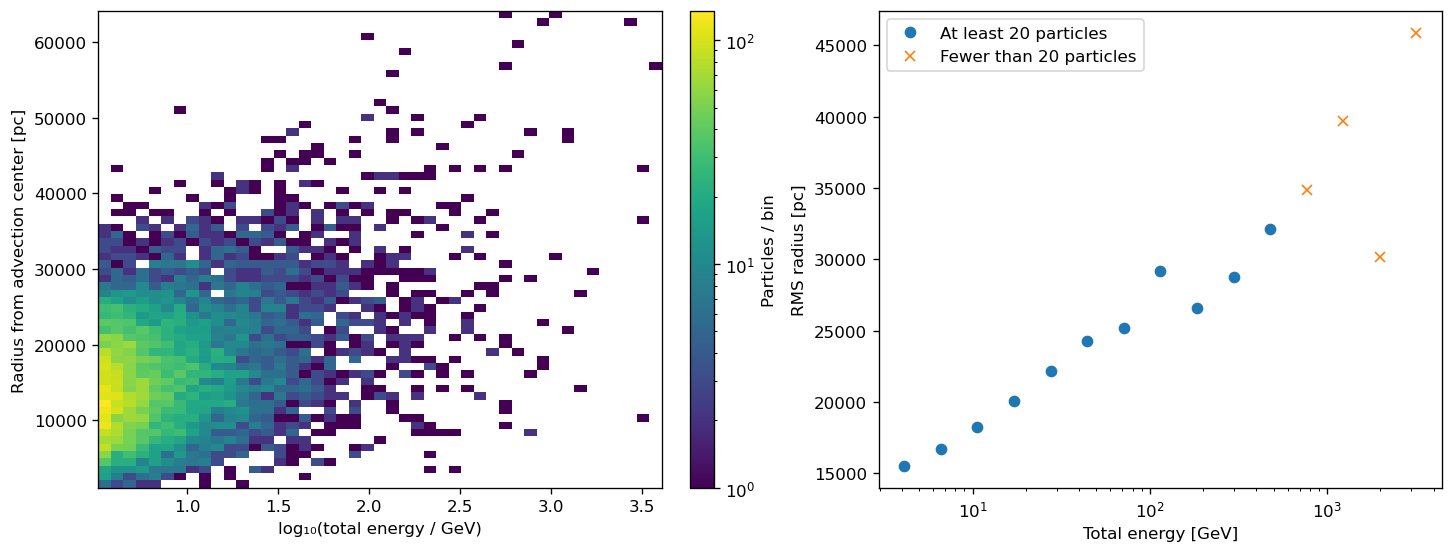

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
h = axes[0].hist2d(np.log10(energy), r, bins=(45, 65), norm=LogNorm(), cmin=1)
axes[0].set(xlabel='log₁₀(total energy / GeV)', ylabel='Radius from advection center [pc]')
fig.colorbar(h[3], ax=axes[0], label='Particles / bin')
redges = np.geomspace(energy.min()*0.999, energy.max()*1.001, 16)
rc = np.sqrt(redges[:-1]*redges[1:])
nr, _ = np.histogram(energy, bins=redges)
sums, _ = np.histogram(energy, bins=redges, weights=r*r)
rms = np.sqrt(np.divide(sums, nr, out=np.full_like(sums, np.nan), where=nr>0))
for selection, marker, label in [(nr>=20, 'o', 'At least 20 particles'), ((nr>0)&(nr<20), 'x', 'Fewer than 20 particles')]:
    axes[1].plot(rc[selection], rms[selection], marker, label=label)
axes[1].set(xscale='log', xlabel='Total energy [GeV]', ylabel='RMS radius [pc]')
axes[1].legend()
plt.show()


## Limitations
Final energies alone do not provide per-particle fractional losses or a measured initial spectrum. Save initial energies and run metadata to quantify those. The current source also retains a full spatial step when truncating the last timestep; shorten that last displacement to match its timestep for consistent diffusion. This notebook does not correct simulation results.


In [5]:
47.99*2

95.98

In [4]:
from pathlib import Path
import re
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
plt.rcParams.update({'figure.dpi': 120})

DATA_FILE = Path('particles_loss_t1e8_dg2gas.bin')
SOURCE_FILE = Path('hadronic_loss.cpp')
source = SOURCE_FILE.read_text()
def parameter(name):
    match = re.search(r'\b' + re.escape(name) + r'\s*=\s*([0-9.eE+\-]+)\s*;', source)
    if match is None:
        match = re.search(r'^\s*#define\s+' + re.escape(name) + r'\s+([0-9.eE+\-]+)', source, re.M)
    if match is None:
        raise ValueError(f'Set {name} manually: cannot read source value.')
    return float(match.group(1))

E_MIN = parameter('E_min')
E_MAX = parameter('E_max')
T_END = parameter('T_end')
VZ = parameter('v_z')
MP = parameter('m_p')
EXPECTED_N = int(parameter('N_particles'))

size = DATA_FILE.stat().st_size
data = np.fromfile(DATA_FILE, dtype='=f8').reshape(-1, 4)

positions, energy = data[:, :3], data[:, 3]
kinetic = energy - MP
n = len(data)

mean = positions.mean(axis=0)
center = np.array([0., 0., VZ*T_END])
r = np.linalg.norm(positions - center, axis=1)
print(f'File: {DATA_FILE}; particles: {n:,}')
print('Mean position [pc]:', mean)
print('Expected advection center [pc]:', center)
print('Coordinate standard deviations [pc]:', positions.std(axis=0, ddof=1))
print('Covariance [pc²]:\n', np.cov(positions, rowvar=False))
print('Total energy min / median / max [GeV]:', np.percentile(energy, [0, 50, 100]))
print('RMS radius about expected center [pc]:', np.sqrt(np.mean(r*r)))


File: particles_loss_t1e8_dg2gas.bin; particles: 10,000
Mean position [pc]: [2.88229709e+02 9.31206417e+01 2.99981906e+06]
Expected advection center [pc]: [      0.       0. 3000000.]
Coordinate standard deviations [pc]: [11354.38581398 11356.8161559  11601.66396391]
Covariance [pc²]:
 [[ 1.28922077e+08  9.82709621e+05 -1.71502394e+06]
 [ 9.82709621e+05  1.28977273e+08 -9.26595664e+05]
 [-1.71502394e+06 -9.26595664e+05  1.34598607e+08]]
Total energy min / median / max [GeV]: [9.87914935e+00 2.00637833e+01 2.75474677e+04]
RMS radius about expected center [pc]: 19813.71229599335


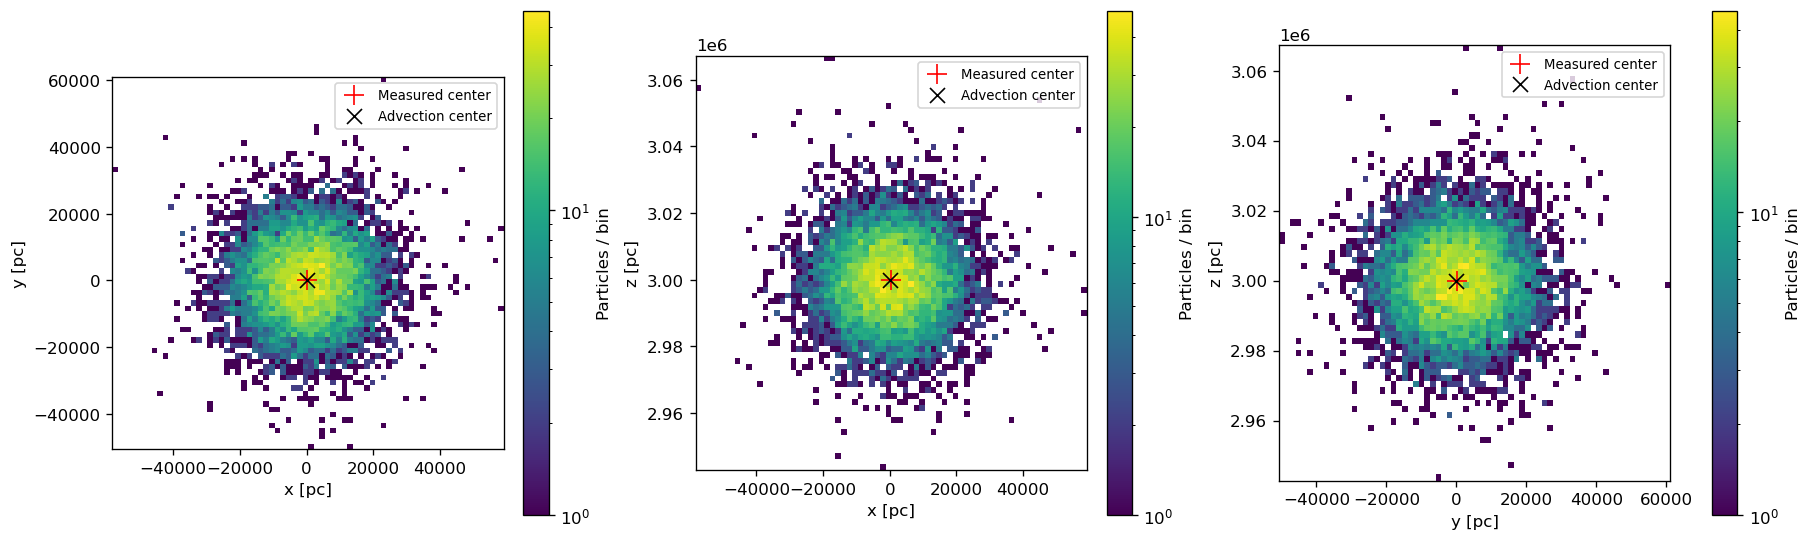

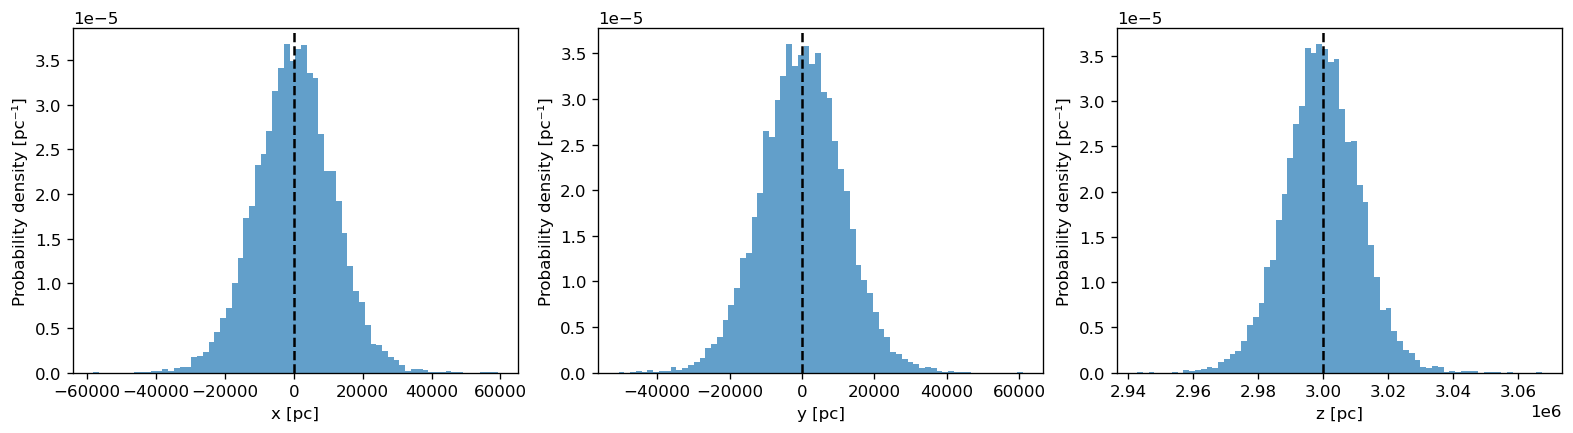

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)
for ax, (a, b) in zip(axes, [(0, 1), (0, 2), (1, 2)]):
    h = ax.hist2d(positions[:, a], positions[:, b], bins=70, norm=LogNorm(), cmin=1)
    ax.plot(mean[a], mean[b], 'r+', ms=12, label='Measured center')
    ax.plot(center[a], center[b], 'kx', ms=9, label='Advection center')
    ax.set(xlabel=f'{"xyz"[a]} [pc]', ylabel=f'{"xyz"[b]} [pc]', aspect='equal')
    ax.legend(fontsize=8)
    fig.colorbar(h[3], ax=ax, label='Particles / bin')
plt.show()
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), constrained_layout=True)
for j, ax in enumerate(axes):
    ax.hist(positions[:, j], bins=70, density=True, alpha=0.7)
    ax.axvline(center[j], color='k', linestyle='--')
    ax.set(xlabel=f'{"xyz"[j]} [pc]', ylabel='Probability density [pc⁻¹]')
plt.show()


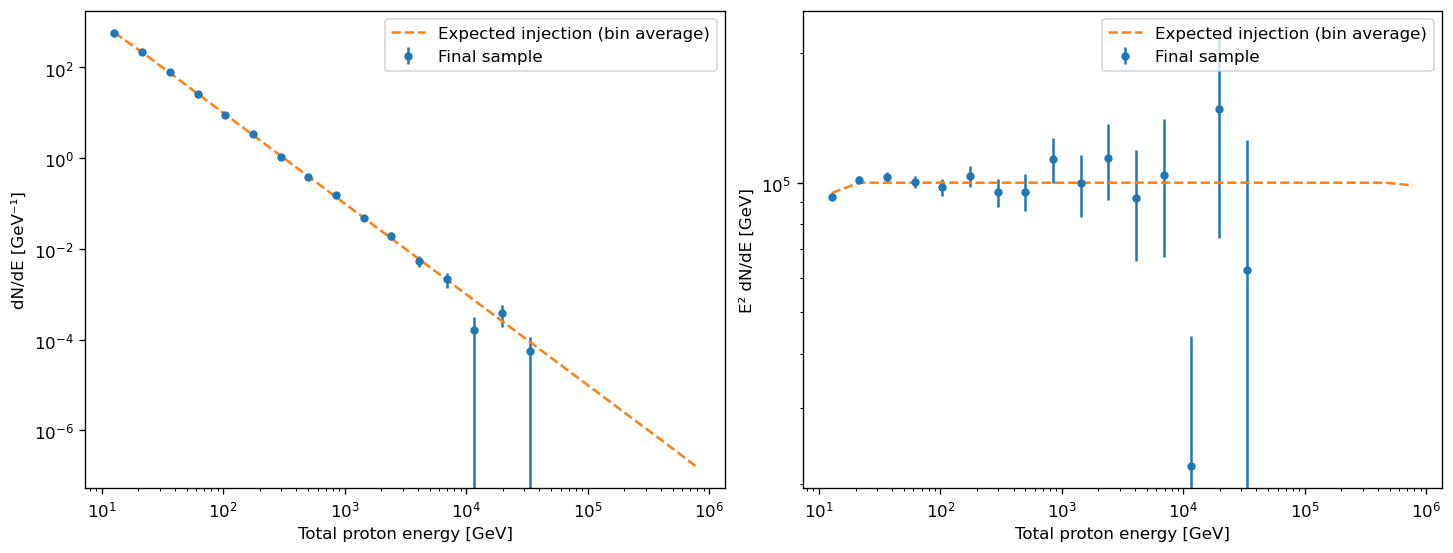

Counts per energy bin: [3872 2510 1506  869  500  313  170  101   71   37   25   12    8    1
    4    1    0    0    0    0    0    0]


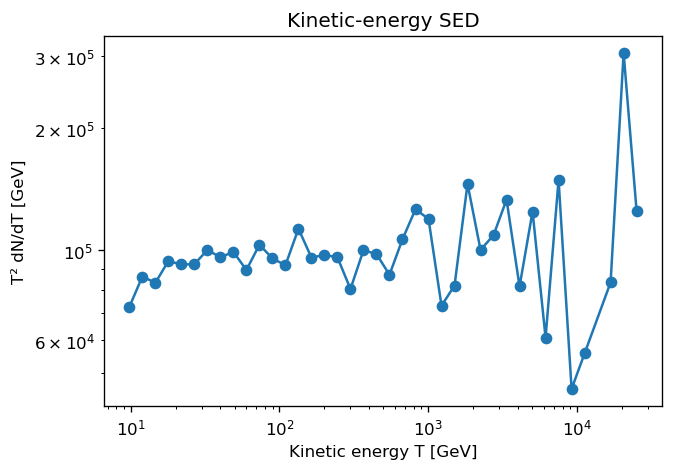

In [6]:
edges = np.geomspace(min(energy.min(), E_MIN)*0.99, max(energy.max(), E_MAX)*1.01, 23)
counts, _ = np.histogram(energy, bins=edges)
widths = np.diff(edges)
ec = np.sqrt(edges[:-1]*edges[1:])
dnde = counts / widths
error = np.sqrt(counts) / widths
mask = counts > 0
C = 1.0 / (1.0/E_MIN - 1.0/E_MAX)
lo = np.maximum(edges[:-1], E_MIN)
hi = np.minimum(edges[1:], E_MAX)
expected_counts = np.zeros_like(ec)
valid = hi > lo
expected_counts[valid] = n*C*(1/lo[valid] - 1/hi[valid])
reference = expected_counts / widths
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for ax, factor, ylabel in zip(axes, [np.ones_like(ec), ec**2],
                              ['dN/dE [GeV⁻¹]', 'E² dN/dE [GeV]']):
    ax.errorbar(ec[mask], (factor*dnde)[mask], yerr=(factor*error)[mask], fmt='o', ms=4, label='Final sample')
    good = reference > 0
    ax.plot(ec[good], (factor*reference)[good], '--', label='Expected injection (bin average)')
    ax.set(xscale='log', yscale='log', xlabel='Total proton energy [GeV]', ylabel=ylabel)
    ax.legend()
plt.show()
print('Counts per energy bin:', counts)
# Kinetic-energy SED: distinct from total-energy SED at lower energies.
kedges = np.geomspace(kinetic.min()*0.99, kinetic.max()*1.01, 41)
kcounts, _ = np.histogram(kinetic, bins=kedges)
kcenters = np.sqrt(kedges[:-1]*kedges[1:])
good = kcounts > 0
fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(kcenters[good], (kcenters**2*kcounts/np.diff(kedges))[good], 'o-')
ax.set(xlabel='Kinetic energy T [GeV]', ylabel='T² dN/dT [GeV]', title='Kinetic-energy SED')
plt.show()


## Monte Carlo diffusion versus physical diffusion
For an isotropic fixed-length displacement, each coordinate has step variance $\lambda^2/3$. Thus the diffusion coefficient represented by the Monte Carlo update is
$$D_{\rm step}(E)=\frac{\lambda(E)^2}{6\Delta t(E)}.$$
The current source uses $\lambda(E)=2(E/\mathrm{GeV})^{1/3}\,\mathrm{pc}$ and $\Delta t=\lambda/(2c)$, giving $D_{\rm step}=c\lambda/3=D_{\rm physical}$ for full steps. These formulas assume independent isotropic directions and a constant vertical wind. Changing the step length or timestep requires updating the parameters below.

We estimate diffusion from the final coordinate variances: $D_a=\mathrm{Var}(a)/(2t)$ and $D_{\rm measured}=\mathrm{tr}(\mathrm{Cov}(\mathbf{x}))/(6t)$. Centering on each sample mean removes constant advection. The plotted error bars estimate sampling uncertainty from the scatter of squared centered displacements; bins with fewer than 30 particles are omitted.

**Interpretation:** the spatial estimator measures the accumulated, time-averaged diffusion of the selected particles. With losses, it need not equal $D(E_{\rm final})$. Selection by final energy can also bias spatial statistics when losses depend on position. The ratio to final-energy diffusion is a diagnostic, not a measurement of artificial diffusion. Isolating a numerical bias requires a fixed-energy, loss-free control run and timestep convergence checks. The existing final truncated timestep retains a full displacement, so the full-step formula does not describe that last step exactly.


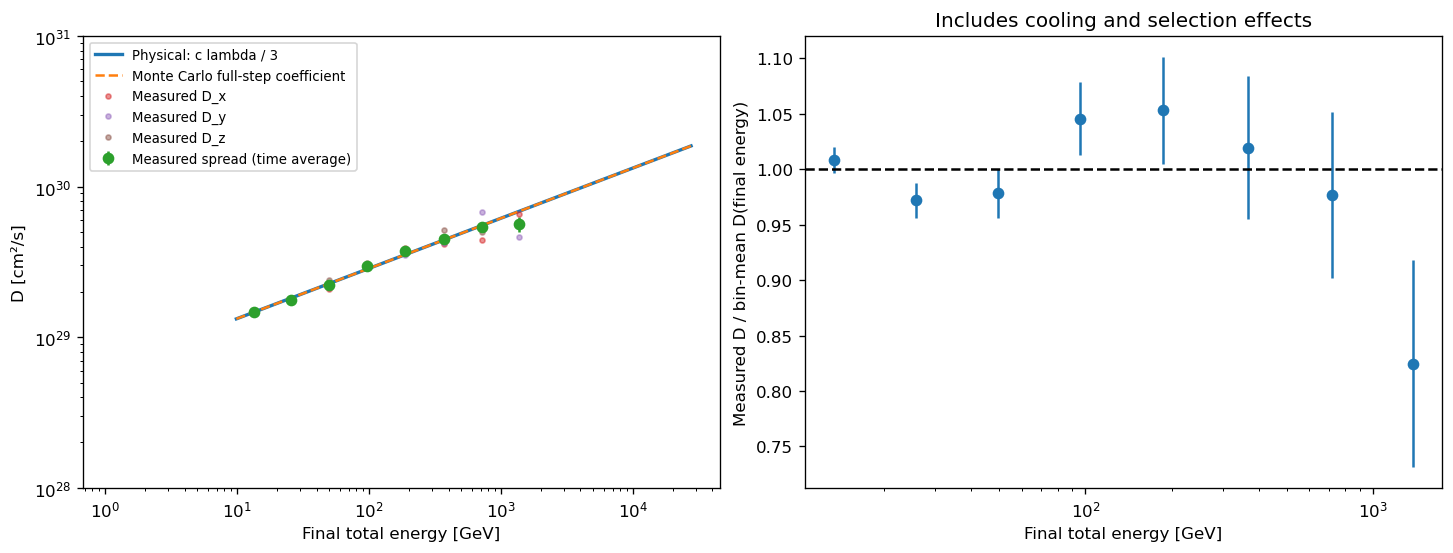

File: particles_loss_t1e8_dg2gas.bin; duration: 1e+08 yr
Full-step D / physical D = 1
Energy [GeV]  count  measured D [cm²/s]  final-energy D [cm²/s]  ratio
       13.37   4746          1.47872e+29            1.46642e+29    1.008
       25.72   2552          1.77302e+29            1.82419e+29    0.972
        49.5   1310          2.22001e+29            2.26891e+29    0.978
       96.08    678          2.96029e+29            2.83067e+29    1.046
       185.8    355          3.71426e+29            3.52631e+29    1.053
       368.1    163          4.51437e+29            4.42774e+29    1.020
       720.3    100          5.41161e+29            5.53915e+29    0.977
        1374     47          5.66600e+29            6.87100e+29    0.825


In [19]:
# Standalone comparison: choose a file and parameters matching its simulation run.
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

DIFFUSION_FILE = Path('particles_loss_t1e8_dg2gas.bin')
DIFFUSION_TIME_YR = 1e8
LAMBDA_NORMALIZATION_PC = 2.0
LAMBDA_ENERGY_INDEX = 1.0 / 3.0
C_PC_YR = 0.30660139
STEP_TIME_DIVISOR = 2.0  # dt = lambda / (STEP_TIME_DIVISOR * c)
MIN_DIFFUSION_COUNT = 30
PC_CM = 3.0856775814913673e18
YEAR_S = 31557600.0
D_UNIT = PC_CM**2 / YEAR_S  # pc²/yr -> cm²/s

raw_diffusion = np.fromfile(DIFFUSION_FILE, dtype='=f8')
if raw_diffusion.size == 0 or raw_diffusion.size % 4:
    raise ValueError('Expected nonempty (x, y, z, E) float64 records.')
diffusion_data = raw_diffusion.reshape(-1, 4)
if not np.isfinite(diffusion_data).all() or np.any(diffusion_data[:, 3] <= 0):
    raise ValueError('Positions and positive total energies must be finite.')
if len(diffusion_data) < MIN_DIFFUSION_COUNT or DIFFUSION_TIME_YR <= 0:
    raise ValueError('Need more particles and a positive simulation duration.')
xyz_diffusion = diffusion_data[:, :3]
energy_diffusion = diffusion_data[:, 3]

def diffusion_lambda(e):
    return LAMBDA_NORMALIZATION_PC * np.asarray(e)**LAMBDA_ENERGY_INDEX

def physical_diffusion(e):
    return C_PC_YR * diffusion_lambda(e) / 3.0

def step_diffusion(e):
    length = diffusion_lambda(e)
    timestep = length / (STEP_TIME_DIVISOR * C_PC_YR)
    return length**2 / (6.0 * timestep)

# Include the maximum-energy particle in the last bin.
diffusion_edges = np.geomspace(energy_diffusion.min() * 0.999,
                               energy_diffusion.max() * 1.001, 13)
rows_diffusion = []
for lower, upper in zip(diffusion_edges[:-1], diffusion_edges[1:]):
    selected = (energy_diffusion >= lower) & (energy_diffusion < upper)
    count = int(selected.sum())
    if count < MIN_DIFFUSION_COUNT:
        continue
    centered = xyz_diffusion[selected] - xyz_diffusion[selected].mean(axis=0)
    square = centered**2
    # ddof=1 correction for the sample coordinate variances.
    d_axes = square.sum(axis=0) / (count - 1) / (2.0 * DIFFUSION_TIME_YR)
    per_particle_d = square.sum(axis=1) / (6.0 * DIFFUSION_TIME_YR)
    correction = count / (count - 1)
    d_error = per_particle_d.std(ddof=1) / np.sqrt(count) * correction
    d_reference = physical_diffusion(energy_diffusion[selected]).mean()
    rows_diffusion.append((np.exp(np.log(energy_diffusion[selected]).mean()),
                           count, *d_axes, d_axes.mean(), d_error, d_reference))
if not rows_diffusion:
    raise ValueError('No sufficiently populated energy bins; reduce the bin count.')
comparison_diffusion = np.asarray(rows_diffusion)
e_bin, counts_bin, dx, dy, dz, d_measured, d_error, d_final = comparison_diffusion.T
energy_grid = np.geomspace(energy_diffusion.min(), energy_diffusion.max(), 200)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
axes[0].loglog(energy_grid, physical_diffusion(energy_grid) * D_UNIT,
               label='Physical: c lambda / 3', lw=2)
axes[0].loglog(energy_grid, step_diffusion(energy_grid) * D_UNIT,
               '--', label='Monte Carlo full-step coefficient')
axes[0].errorbar(e_bin, d_measured * D_UNIT, yerr=d_error * D_UNIT,
                 fmt='o', label='Measured spread (time average)')
for values, label in [(dx, 'x'), (dy, 'y'), (dz, 'z')]:
    axes[0].loglog(e_bin, values * D_UNIT, '.', alpha=0.5, label=f'Measured D_{label}')
axes[0].set(xlabel='Final total energy [GeV]', ylabel='D [cm²/s]')
axes[0].legend(fontsize=8)
axes[0].set_ylim(1e28,1e31)
axes[1].errorbar(e_bin, d_measured / d_final, yerr=d_error / d_final, fmt='o')
axes[1].axhline(1.0, color='k', linestyle='--')
axes[1].set(xscale='log', xlabel='Final total energy [GeV]',
            ylabel='Measured D / bin-mean D(final energy)',
            title='Includes cooling and selection effects')
plt.show()
print(f'File: {DIFFUSION_FILE}; duration: {DIFFUSION_TIME_YR:g} yr')
print(f'Full-step D / physical D = {STEP_TIME_DIVISOR / 2:g}')
print('Energy [GeV]  count  measured D [cm²/s]  final-energy D [cm²/s]  ratio')
for e, count, measured, reference in zip(e_bin, counts_bin, d_measured, d_final):
    print(f'{e:12.4g} {int(count):6d} {measured*D_UNIT:20.5e} '
          f'{reference*D_UNIT:22.5e} {measured/reference:8.3f}')


In [2]:
18.3 / (10000 / 40)

0.0732

In [3]:
18.3*100/10

183.0